# RLMmejorecuacion — Concrete_Data.csv

**Regresión lineal múltiple: selección de predictores y comparación de ecuaciones**

Este trabajo adapta el análisis `RLMmejorecuacion` a la base de concreto. La respuesta es la resistencia a compresión (MPa); los predictores son los siete componentes de la mezcla y la edad. Se comparan métodos de filtro, selección wrapper, regularización y un bosque aleatorio de referencia.

El conjunto de prueba se reserva hasta la evaluación final. La selección de variables y la validación cruzada se realizan usando únicamente entrenamiento.

## 1. Librerías y carga de datos

El notebook usa `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn` y `statsmodels`. Si falta alguna, puedes instalarlas ejecutando `pip install pandas numpy matplotlib seaborn scikit-learn statsmodels` en el entorno de Jupyter.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression, RFE, RFECV, SequentialFeatureSelector
from sklearn.ensemble import RandomForestRegressor
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

candidatos = [Path("Concrete_Data.csv"), Path("../../Concrete_Data.csv"), Path("../Concrete_Data.csv")]
archivo = next((p for p in candidatos if p.exists()), None)
if archivo is None:
    raise FileNotFoundError("No se encontró Concrete_Data.csv; ejecuta el notebook desde el proyecto o Tarea3.")

nombres = ["cemento", "escoria", "ceniza_volante", "agua", "superplastificante",
           "agregado_grueso", "agregado_fino", "edad_dias", "resistencia_mpa"]
datos = pd.read_csv(archivo)
if datos.shape[1] != len(nombres):
    raise ValueError(f"Se esperaban 9 columnas y se encontraron {datos.shape[1]}.")
datos.columns = nombres
datos = datos.apply(pd.to_numeric, errors="coerce")
print(f"Archivo: {archivo.name}")
print(f"Dimensiones: {datos.shape[0]} filas × {datos.shape[1]} columnas")
datos.head()

Archivo: Concrete_Data.csv
Dimensiones: 1030 filas × 9 columnas


,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,resistencia_mpa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


## 2. Revisión exploratoria

Revisa rangos y distribución antes de ajustar modelos. Las filas repetidas se reportan; para mantener la comparación con la base original, no se eliminan en este análisis.

In [2]:
print("Tipos de datos:")
print(datos.dtypes)
print("\nFaltantes:")
print(datos.isna().sum())
print("Duplicados exactos:", int(datos.duplicated().sum()))
datos.describe().T.round(2)

Tipos de datos:
cemento               float64
escoria               float64
ceniza_volante        float64
agua                  float64
superplastificante    float64
agregado_grueso       float64
agregado_fino         float64
edad_dias               int64
resistencia_mpa       float64
dtype: object

Faltantes:
cemento               0
escoria               0
ceniza_volante        0
agua                  0
superplastificante    0
agregado_grueso       0
agregado_fino         0
edad_dias             0
resistencia_mpa       0
dtype: int64
Duplicados exactos: 25


,count,mean,std,min,25%,50%,75%,max
cemento,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
escoria,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
ceniza_volante,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
agua,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
superplastificante,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
agregado_grueso,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
agregado_fino,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
edad_dias,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
resistencia_mpa,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


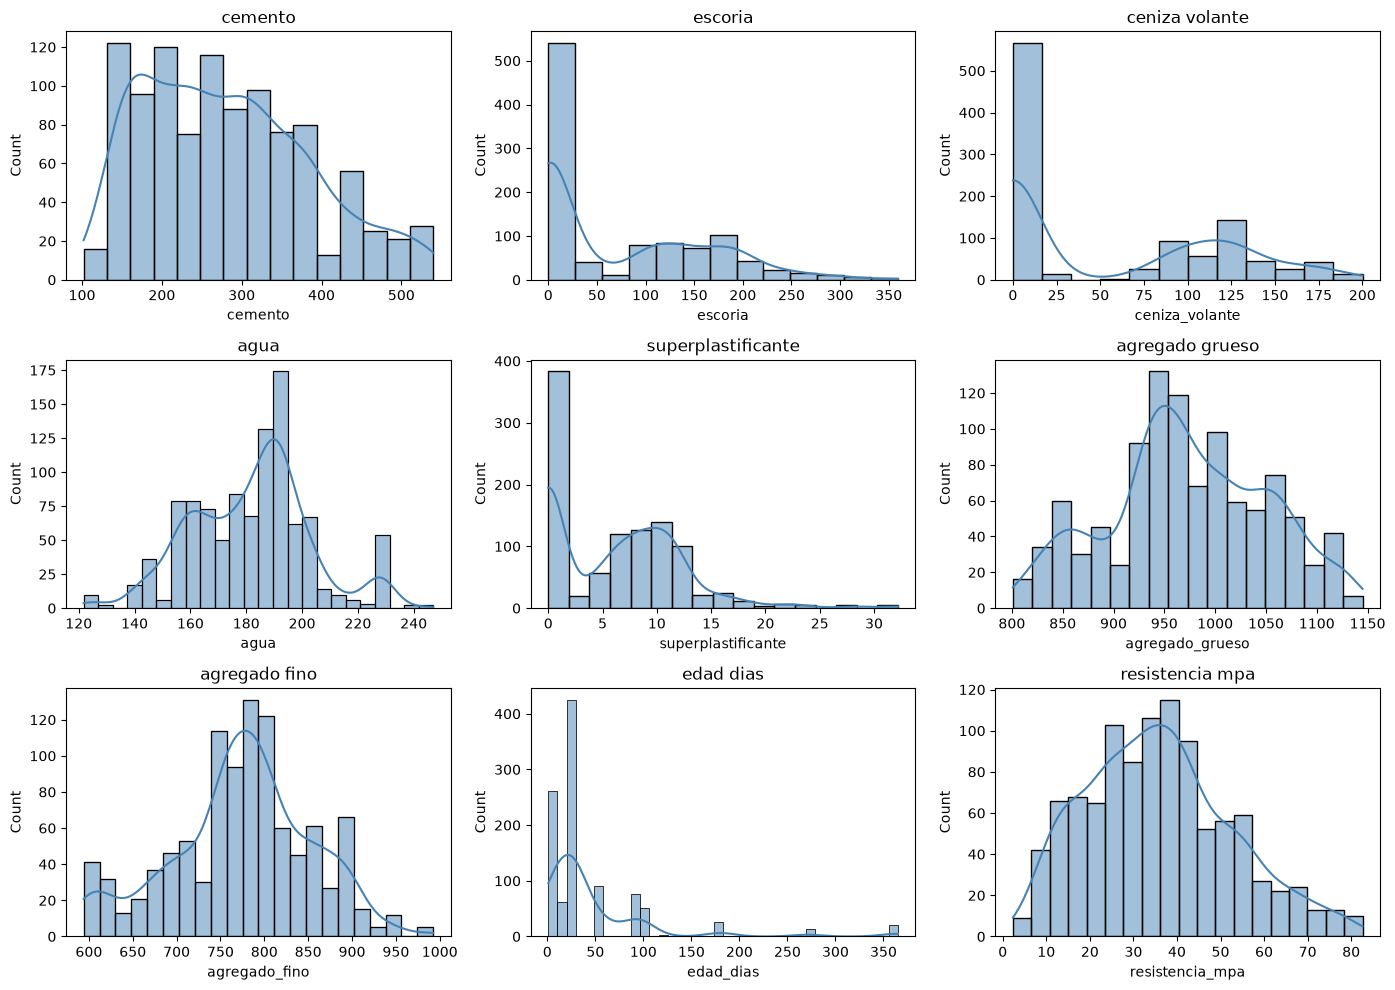

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, datos.columns):
    sns.histplot(data=datos, x=col, kde=True, ax=ax, color="steelblue")
    ax.set_title(col.replace("_", " "))
plt.tight_layout()
plt.show()

## 3. Correlación con la resistencia

Pearson resume asociaciones lineales de cada predictor con la respuesta. Es una exploración univariada: no controla por los demás componentes.

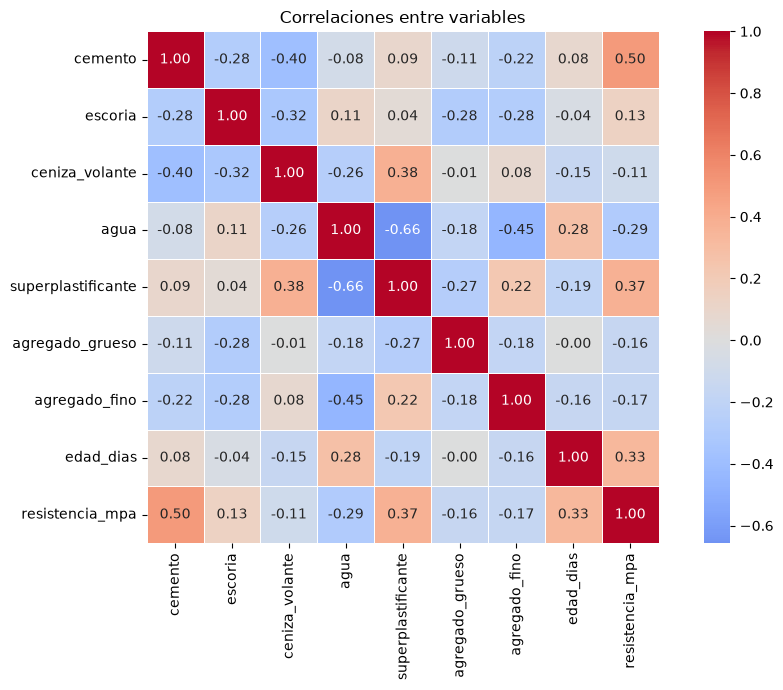

Correlación de Pearson con resistencia:
cemento               0.498
superplastificante    0.366
edad_dias             0.329
agua                 -0.290
agregado_fino        -0.167
agregado_grueso      -0.165
escoria               0.135
ceniza_volante       -0.106
Name: resistencia_mpa, dtype: float64


In [4]:
correlaciones = datos.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=.4, ax=ax)
ax.set_title("Correlaciones entre variables")
plt.tight_layout()
plt.show()

corr_y = correlaciones["resistencia_mpa"].drop("resistencia_mpa").sort_values(key=np.abs, ascending=False)
print("Correlación de Pearson con resistencia:")
print(corr_y.round(3))

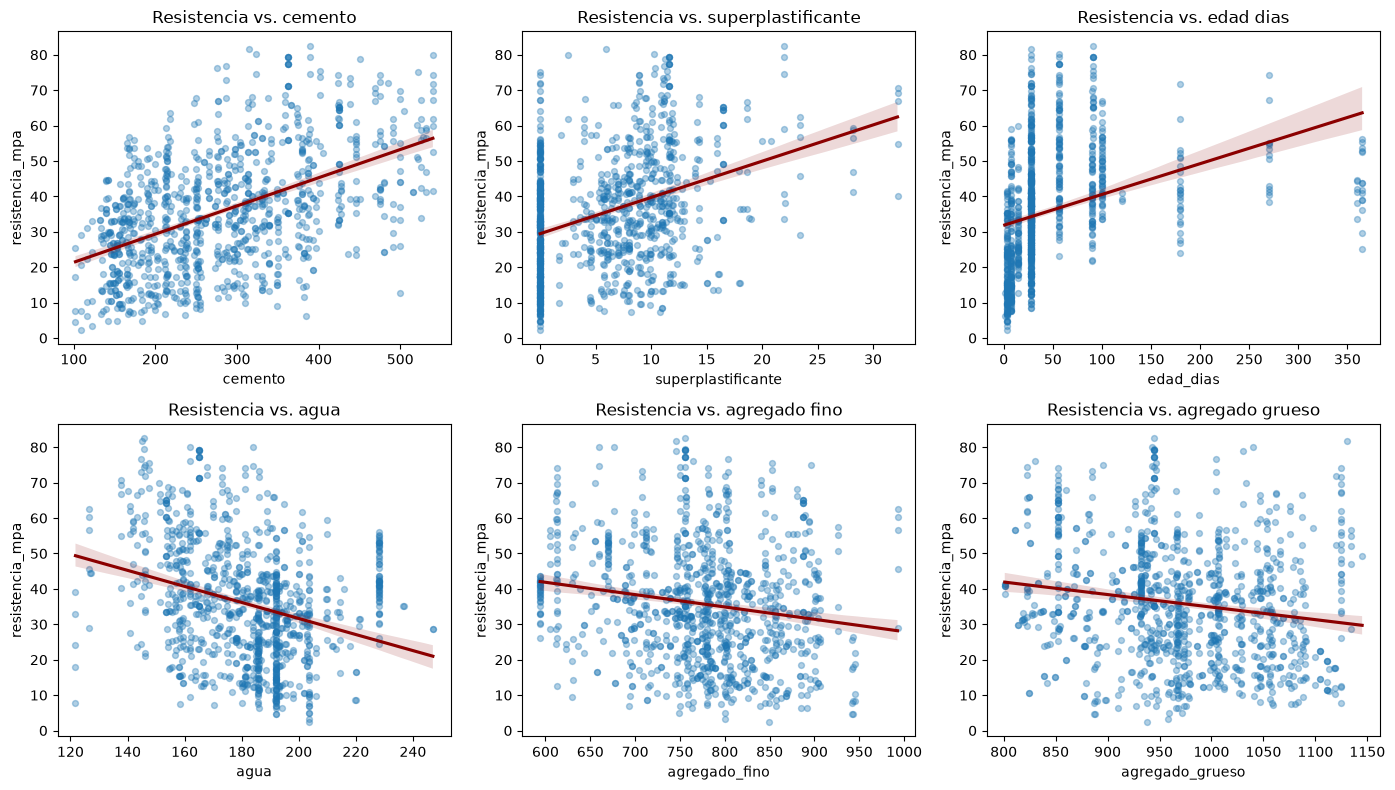

In [5]:
top_vars = corr_y.abs().head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, top_vars):
    sns.regplot(data=datos, x=col, y="resistencia_mpa", ax=ax,
                scatter_kws={"alpha": .35, "s": 18}, line_kws={"color": "darkred"})
    ax.set_title(f"Resistencia vs. {col.replace('_', ' ')}")
plt.tight_layout()
plt.show()

## 4. Preparación y modelo base

Se usa una partición aleatoria 80/20. El escalador se ajusta solo con entrenamiento para evitar filtrar información del test. Las escalas estandarizadas facilitan comparar coeficientes y métodos penalizados.

In [6]:
respuesta = "resistencia_mpa"
feature_names = [c for c in datos.columns if c != respuesta]
X = datos[feature_names]
y = datos[respuesta]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=.8, random_state=42, shuffle=True
)
scaler = StandardScaler()
X_train_sc = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_names, index=X_train.index)
X_test_sc = pd.DataFrame(scaler.transform(X_test), columns=feature_names, index=X_test.index)
print(f"Entrenamiento: {len(X_train)} filas | Prueba: {len(X_test)} filas")
X_train_sc.head()

Entrenamiento: 824 filas | Prueba: 206 filas


,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias
995,-1.160846,0.857395,0.982474,-0.314231,1.481991,-0.257457,-0.647505,-0.275673
507,1.308634,-0.602489,1.232625,-0.178148,0.388662,-1.926947,-0.273130,-0.275673
334,-0.077122,-0.855581,1.066118,-1.047204,0.626779,1.017866,0.066649,-0.689313
848,-0.291783,0.260327,0.357096,0.572657,0.308171,-1.761651,0.604117,-0.275673
294,-1.065193,-0.369874,1.111458,-1.101168,0.782730,1.363716,0.297081,-0.689313


In [7]:
resultados = []
def evaluar_modelo(Xtr, Xte, ytr, yte, nombre, estimador=None):
    modelo = estimador if estimador is not None else LinearRegression()
    modelo.fit(Xtr, ytr)
    pred_train = modelo.predict(Xtr)
    pred_test = modelo.predict(Xte)
    cv = cross_val_score(LinearRegression(), Xtr, ytr, cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
    fila = {"Método": nombre,
            "Variables": list(Xtr.columns),
            "n_variables": Xtr.shape[1],
            "R²_train": r2_score(ytr, pred_train),
            "R²_test": r2_score(yte, pred_test),
            "RMSE_test": np.sqrt(mean_squared_error(yte, pred_test)),
            "MAE_test": mean_absolute_error(yte, pred_test),
            "CV_R²_media": cv.mean(),
            "CV_R²_sd": cv.std()}
    resultados.append(fila)
    print(f"{nombre}: R² test={fila['R²_test']:.4f} | RMSE={fila['RMSE_test']:.3f} MPa | CV R²={cv.mean():.4f} ± {cv.std():.4f}")
    return modelo

print("MODELO BASE — todos los predictores")
modelo_base = evaluar_modelo(X_train_sc, X_test_sc, y_train, y_test, "Base: todas")

MODELO BASE — todos los predictores
Base: todas: R² test=0.6275 | RMSE=9.797 MPa | CV R²=0.5971 ± 0.0473


## 5. Métodos de filtro

Los filtros puntúan variables antes de ajustar un modelo múltiple. Se usan Pearson, F-test, información mutua y VIF. VIF alto sugiere que un predictor se puede explicar mediante los demás; no mide su relación con la respuesta.

In [8]:
print("Correlación de Pearson absoluta con la respuesta (train):")
corr_train = X_train_sc.corrwith(y_train).abs().sort_values(ascending=False)
print(corr_train.round(3))

selector_f = SelectKBest(score_func=f_regression, k="all").fit(X_train_sc, y_train)
ftest = pd.DataFrame({"variable": feature_names, "F": selector_f.scores_, "p_valor": selector_f.pvalues_}).sort_values("F", ascending=False)
print("\nF-test:")
print(ftest.round(4).to_string(index=False))

selector_mi = SelectKBest(score_func=mutual_info_regression, k="all").fit(X_train_sc, y_train)
mutua = pd.Series(selector_mi.scores_, index=feature_names, name="informacion_mutua").sort_values(ascending=False)
print("\nInformación mutua:")
print(mutua.round(4))

Correlación de Pearson absoluta con la respuesta (train):
cemento               0.497
superplastificante    0.353
edad_dias             0.332
agua                  0.285
agregado_grueso       0.172
agregado_fino         0.158
escoria               0.155
ceniza_volante        0.150
dtype: float64

F-test:
          variable        F  p_valor
           cemento 269.1973      0.0
superplastificante 117.2125      0.0
         edad_dias 101.8841      0.0
              agua  72.4346      0.0
   agregado_grueso  24.9405      0.0
     agregado_fino  21.1629      0.0
           escoria  20.2751      0.0
    ceniza_volante  18.8556      0.0

Información mutua:
edad_dias             0.3316
agua                  0.3292
cemento               0.2852
escoria               0.2187
agregado_grueso       0.2083
superplastificante    0.2034
agregado_fino         0.1654
ceniza_volante        0.1036
Name: informacion_mutua, dtype: float64


In [9]:
def calcular_vif(X_df):
    matriz = sm.add_constant(X_df, has_constant="add")
    return pd.DataFrame({"variable": X_df.columns,
                         "VIF": [variance_inflation_factor(matriz.to_numpy(), i + 1)
                                 for i in range(X_df.shape[1])]})

X_vif = X_train_sc.copy()
while X_vif.shape[1] > 2:
    tabla_vif = calcular_vif(X_vif).replace([np.inf, -np.inf], np.inf)
    max_row = tabla_vif.loc[tabla_vif["VIF"].idxmax()]
    if max_row["VIF"] <= 10:
        break
    print(f"Se retira {max_row['variable']} (VIF={max_row['VIF']:.2f})")
    X_vif = X_vif.drop(columns=max_row["variable"])
print("\nVIF final:")
print(calcular_vif(X_vif).round(3).to_string(index=False))
modelo_vif = evaluar_modelo(X_train_sc[X_vif.columns], X_test_sc[X_vif.columns],
                            y_train, y_test, "Filtro VIF")


VIF final:
          variable   VIF
           cemento 7.489
           escoria 7.129
    ceniza_volante 6.028
              agua 6.512
superplastificante 2.850
   agregado_grueso 4.924
     agregado_fino 6.773
         edad_dias 1.111
Filtro VIF: R² test=0.6275 | RMSE=9.797 MPa | CV R²=0.5971 ± 0.0473


## 6. Métodos wrapper

Los métodos wrapper evalúan subconjuntos según el desempeño predictivo. RFE y RFECV eliminan variables recursivamente; selección secuencial agrega o retira predictores con validación cruzada.

In [10]:
n_objetivo = max(1, len(feature_names) // 2)
rfe = RFE(estimator=LinearRegression(), n_features_to_select=n_objetivo)
rfe.fit(X_train_sc, y_train)
vars_rfe = [v for v, conservar in zip(feature_names, rfe.support_) if conservar]
print("RFE:", vars_rfe)
modelo_rfe = evaluar_modelo(X_train_sc[vars_rfe], X_test_sc[vars_rfe], y_train, y_test, "RFE")

rfecv = RFECV(estimator=LinearRegression(), step=1,
              cv=KFold(5, shuffle=True, random_state=42), scoring="r2",
              min_features_to_select=1)
rfecv.fit(X_train_sc, y_train)
vars_rfecv = [v for v, conservar in zip(feature_names, rfecv.support_) if conservar]
print("RFECV seleccionó:", vars_rfecv)
modelo_rfecv = evaluar_modelo(X_train_sc[vars_rfecv], X_test_sc[vars_rfecv],
                              y_train, y_test, "RFECV")

RFE: ['cemento', 'escoria', 'agua', 'edad_dias']
RFE: R² test=0.5303 | RMSE=11.001 MPa | CV R²=0.5506 ± 0.0470
RFECV seleccionó: ['cemento', 'escoria', 'ceniza_volante', 'agua', 'superplastificante', 'agregado_grueso', 'agregado_fino', 'edad_dias']
RFECV: R² test=0.6275 | RMSE=9.797 MPa | CV R²=0.5971 ± 0.0473


In [11]:
sfs_forward = SequentialFeatureSelector(
    LinearRegression(), n_features_to_select=n_objetivo, direction="forward",
    scoring="r2", cv=KFold(5, shuffle=True, random_state=42), n_jobs=1)
sfs_forward.fit(X_train_sc, y_train)
vars_forward = list(X_train_sc.columns[sfs_forward.get_support()])
print("Forward:", vars_forward)
modelo_forward = evaluar_modelo(X_train_sc[vars_forward], X_test_sc[vars_forward],
                                y_train, y_test, "Wrapper forward")

sfs_backward = SequentialFeatureSelector(
    LinearRegression(), n_features_to_select=n_objetivo, direction="backward",
    scoring="r2", cv=KFold(5, shuffle=True, random_state=42), n_jobs=1)
sfs_backward.fit(X_train_sc, y_train)
vars_backward = list(X_train_sc.columns[sfs_backward.get_support()])
print("Backward:", vars_backward)
modelo_backward = evaluar_modelo(X_train_sc[vars_backward], X_test_sc[vars_backward],
                                 y_train, y_test, "Wrapper backward")

Forward: ['cemento', 'escoria', 'superplastificante', 'edad_dias']
Wrapper forward: R² test=0.5259 | RMSE=11.053 MPa | CV R²=0.5408 ± 0.0583


Backward: ['cemento', 'escoria', 'agua', 'edad_dias']
Wrapper backward: R² test=0.5303 | RMSE=11.001 MPa | CV R²=0.5506 ± 0.0470


### Selección hacia adelante y hacia atrás por AIC

AIC equilibra ajuste y cantidad de parámetros. El proceso se realiza sobre entrenamiento y usa `statsmodels` para volver a estimar la ecuación en cada paso.

In [12]:
def ajustar_ols(columnas):
    X_sm = sm.add_constant(X_train_sc[columnas], has_constant="add")
    return sm.OLS(y_train, X_sm).fit()

def seleccion_forward_aic():
    disponibles = list(feature_names)
    elegidas = []
    actual = ajustar_ols(elegidas).aic
    while disponibles:
        candidatos = [(ajustar_ols(elegidas + [v]).aic, v) for v in disponibles]
        mejor_aic, variable = min(candidatos)
        if mejor_aic >= actual:
            break
        elegidas.append(variable)
        disponibles.remove(variable)
        actual = mejor_aic
        print(f"Agrega {variable}: AIC={actual:.2f}")
    return elegidas

def seleccion_backward_aic():
    elegidas = list(feature_names)
    actual = ajustar_ols(elegidas).aic
    while len(elegidas) > 1:
        candidatos = [(ajustar_ols([v for v in elegidas if v != quitar]).aic, quitar) for quitar in elegidas]
        mejor_aic, variable = min(candidatos)
        if mejor_aic >= actual:
            break
        elegidas.remove(variable)
        actual = mejor_aic
        print(f"Retira {variable}: AIC={actual:.2f}")
    return elegidas

vars_forward_aic = seleccion_forward_aic()
vars_backward_aic = seleccion_backward_aic()
print("\nForward AIC:", vars_forward_aic)
print("Backward AIC:", vars_backward_aic)
modelo_forward_aic = evaluar_modelo(X_train_sc[vars_forward_aic], X_test_sc[vars_forward_aic],
                                   y_train, y_test, "AIC forward")
modelo_backward_aic = evaluar_modelo(X_train_sc[vars_backward_aic], X_test_sc[vars_backward_aic],
                                    y_train, y_test, "AIC backward")

Agrega cemento: AIC=6763.97
Agrega superplastificante: AIC=6649.03
Agrega edad_dias: AIC=6478.82
Agrega escoria: AIC=6336.04
Agrega agua: AIC=6277.78
Agrega ceniza_volante: AIC=6234.71

Forward AIC: ['cemento', 'superplastificante', 'edad_dias', 'escoria', 'agua', 'ceniza_volante']
Backward AIC: ['cemento', 'escoria', 'ceniza_volante', 'agua', 'superplastificante', 'agregado_grueso', 'agregado_fino', 'edad_dias']
AIC forward: R² test=0.6288 | RMSE=9.780 MPa | CV R²=0.5956 ± 0.0469
AIC backward: R² test=0.6275 | RMSE=9.797 MPa | CV R²=0.5971 ± 0.0473


## 7. Métodos embebidos: Lasso y Ridge

Lasso aplica penalización L1 y puede llevar coeficientes a cero; Ridge aplica penalización L2 y reduce coeficientes sin eliminarlos. La validación cruzada selecciona `alpha` usando entrenamiento.

In [13]:
lasso_cv = LassoCV(cv=KFold(5, shuffle=True, random_state=42), random_state=42,
                   max_iter=50000, alphas=100).fit(X_train_sc, y_train)
vars_lasso = [v for v, coef in zip(feature_names, lasso_cv.coef_) if abs(coef) > 1e-8]
print(f"Alpha Lasso: {lasso_cv.alpha_:.6g}")
print(pd.Series(lasso_cv.coef_, index=feature_names, name="coeficiente").sort_values(key=np.abs, ascending=False).round(4))
if not vars_lasso:
    vars_lasso = [feature_names[int(np.argmax(np.abs(lasso_cv.coef_)))]]
pred_lasso = lasso_cv.predict(X_test_sc)
cv_lasso = cross_val_score(LassoCV(cv=5, random_state=42, max_iter=50000),
                           X_train_sc, y_train,
                           cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
resultados.append({"Método": "LassoCV", "Variables": vars_lasso,
                   "n_variables": len(vars_lasso),
                   "R²_train": lasso_cv.score(X_train_sc, y_train),
                   "R²_test": r2_score(y_test, pred_lasso),
                   "RMSE_test": np.sqrt(mean_squared_error(y_test, pred_lasso)),
                   "MAE_test": mean_absolute_error(y_test, pred_lasso),
                   "CV_R²_media": cv_lasso.mean(), "CV_R²_sd": cv_lasso.std()})
print(f"LassoCV real: R² test={r2_score(y_test,pred_lasso):.4f} | RMSE={np.sqrt(mean_squared_error(y_test,pred_lasso)):.3f} MPa | CV R²={cv_lasso.mean():.4f}")

ridge_cv = RidgeCV(alphas=np.logspace(-3, 4, 100), cv=KFold(5, shuffle=True, random_state=42))
ridge_cv.fit(X_train_sc, y_train)
y_pred_ridge = ridge_cv.predict(X_test_sc)
ridge_fila = {"Método": "Ridge", "Variables": feature_names, "n_variables": len(feature_names),
              "R²_train": ridge_cv.score(X_train_sc, y_train),
              "R²_test": r2_score(y_test, y_pred_ridge),
              "RMSE_test": np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
              "MAE_test": mean_absolute_error(y_test, y_pred_ridge),
              "CV_R²_media": np.nan, "CV_R²_sd": np.nan}
resultados.append(ridge_fila)
print(f"Alpha Ridge: {ridge_cv.alpha_:.6g} | R² test={ridge_fila['R²_test']:.4f} | RMSE={ridge_fila['RMSE_test']:.3f} MPa")

Alpha Lasso: 0.00837155
cemento               12.5659
escoria                9.2150
edad_dias              7.0176
ceniza_volante         5.0666
agua                  -3.0515
superplastificante     1.8239
agregado_fino          1.7422
agregado_grueso        1.2335
Name: coeficiente, dtype: float64


LassoCV real: R² test=0.6275 | RMSE=9.797 MPa | CV R²=0.5956

Alpha Ridge: 0.572237 | R² test=0.6276 | RMSE=9.796 MPa


### Eliminación iterativa por p-valor

Se elimina el predictor con mayor p-valor hasta que los restantes cumplen el umbral 0.05. Los p-valores dependen de los supuestos del modelo lineal y se interpretan junto con el diagnóstico de residuos.

In [14]:
vars_p = list(feature_names)
while len(vars_p) > 1:
    fit = sm.OLS(y_train, sm.add_constant(X_train_sc[vars_p], has_constant="add")).fit()
    pvals = fit.pvalues.drop("const")
    variable = pvals.idxmax()
    if pvals[variable] <= 0.05:
        break
    print(f"Se elimina {variable}: p={pvals[variable]:.4g}")
    vars_p.remove(variable)
print("Variables por p-valor:", vars_p)
modelo_p = evaluar_modelo(X_train_sc[vars_p], X_test_sc[vars_p], y_train, y_test,
                          "P-valores (OLS)")
print(sm.OLS(y_train, sm.add_constant(X_train_sc[vars_p], has_constant="add")).fit().summary())

Se elimina agregado_grueso: p=0.08719
Se elimina agregado_fino: p=0.2756
Variables por p-valor: ['cemento', 'escoria', 'ceniza_volante', 'agua', 'superplastificante', 'edad_dias']
P-valores (OLS): R² test=0.6288 | RMSE=9.780 MPa | CV R²=0.5956 ± 0.0469
                            OLS Regression Results                            
Dep. Variable:        resistencia_mpa   R-squared:                       0.608
Model:                            OLS   Adj. R-squared:                  0.606
Method:                 Least Squares   F-statistic:                     211.6
Date:                Sun, 18 Oct 2026   Prob (F-statistic):          1.35e-162
Time:                        01:30:38   Log-Likelihood:                -3110.4
No. Observations:                 824   AIC:                             6235.
Df Residuals:                     817   BIC:                             6268.
Df Model:                           6                                         
Covariance Type:            nonrobus

## 8. Bosque aleatorio y comparación final

Se añade un bosque aleatorio como referencia no lineal. Su importancia de variables es predictiva y no representa efectos causales. El ajuste de hiperparámetros se valida dentro del conjunto de entrenamiento.

In [15]:
bosque_base = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=1)
bosque_base.fit(X_train, y_train)
p_bosque_base = bosque_base.predict(X_test)
print(f"Bosque base | R² test={r2_score(y_test,p_bosque_base):.4f} | RMSE={np.sqrt(mean_squared_error(y_test,p_bosque_base)):.3f} MPa")

param_grid = {"n_estimators": [200, 400], "max_depth": [None, 8],
              "min_samples_leaf": [1, 3]}
busqueda = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=1),
                        param_grid=param_grid, cv=KFold(5, shuffle=True, random_state=42),
                        scoring="neg_root_mean_squared_error", n_jobs=1)
busqueda.fit(X_train, y_train)
mejor_bosque = busqueda.best_estimator_
p_bosque = mejor_bosque.predict(X_test)
rf_fila = {"Método": "Random Forest (CV)", "Variables": feature_names, "n_variables": len(feature_names),
           "R²_train": mejor_bosque.score(X_train,y_train), "R²_test": r2_score(y_test,p_bosque),
           "RMSE_test": np.sqrt(mean_squared_error(y_test,p_bosque)),
           "MAE_test": mean_absolute_error(y_test,p_bosque),
           "CV_R²_media": np.nan, "CV_R²_sd": np.nan}
resultados.append(rf_fila)
print("Mejores parámetros:", busqueda.best_params_)
importancias = pd.Series(mejor_bosque.feature_importances_, index=feature_names).sort_values(ascending=False)
print("\nImportancia de variables:")
print(importancias.round(4))

Bosque base | R² test=0.8789 | RMSE=5.586 MPa


Mejores parámetros: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 400}

Importancia de variables:
edad_dias             0.3320
cemento               0.3283
agua                  0.1242
escoria               0.0758
superplastificante    0.0558
agregado_fino         0.0363
agregado_grueso       0.0282
ceniza_volante        0.0194
dtype: float64


In [16]:
tabla_resultados = pd.DataFrame(resultados).drop_duplicates(subset="Método", keep="last")
tabla_resultados = tabla_resultados.sort_values("RMSE_test").reset_index(drop=True)
columnas = ["Método", "n_variables", "R²_train", "R²_test", "RMSE_test", "MAE_test", "CV_R²_media", "CV_R²_sd"]
tabla_resultados[columnas].round(4)

,Método,n_variables,R²_train,R²_test,RMSE_test,MAE_test,CV_R²_media,CV_R²_sd
0,Random Forest (CV),8,0.9872,0.8807,5.5456,3.7953,NaN,NaN
1,P-valores (OLS),6,0.6085,0.6288,9.7797,7.7633,0.5956,0.0469
2,AIC forward,6,0.6085,0.6288,9.7797,7.7633,0.5956,0.0469
3,Ridge,8,0.6105,0.6276,9.7965,7.7491,NaN,NaN
4,LassoCV,8,0.6104,0.6275,9.7966,7.7511,0.5956,0.0463
5,Base: todas,8,0.6105,0.6275,9.7967,7.7454,0.5971,0.0473
6,RFECV,8,0.6105,0.6275,9.7967,7.7454,0.5971,0.0473
7,Filtro VIF,8,0.6105,0.6275,9.7967,7.7454,0.5971,0.0473
8,AIC backward,8,0.6105,0.6275,9.7967,7.7454,0.5971,0.0473
9,RFE,4,0.5626,0.5303,11.0011,8.9189,0.5506,0.0470


## 9. Ecuación mejorada y diagnóstico

Se toma como candidata principal la ecuación backward por AIC. Se muestran coeficientes, significancia y gráficos diagnósticos. La tabla final permite contrastarla con los demás métodos; el criterio de elección debe considerar el error de prueba y la interpretabilidad.

In [17]:
vars_mejor = vars_backward_aic
modelo_mejor = sm.OLS(y_train, sm.add_constant(X_train_sc[vars_mejor], has_constant="add")).fit()
pred_mejor = modelo_mejor.predict(sm.add_constant(X_test_sc[vars_mejor], has_constant="add"))
print("Variables de la ecuación mejorada:", vars_mejor)
print(modelo_mejor.summary())
print(f"\nDesempeño de la ecuación mejorada: R² test={r2_score(y_test,pred_mejor):.4f} | RMSE={np.sqrt(mean_squared_error(y_test,pred_mejor)):.3f} MPa | MAE={mean_absolute_error(y_test,pred_mejor):.3f} MPa")

Variables de la ecuación mejorada: ['cemento', 'escoria', 'ceniza_volante', 'agua', 'superplastificante', 'agregado_grueso', 'agregado_fino', 'edad_dias']
                            OLS Regression Results                            
Dep. Variable:        resistencia_mpa   R-squared:                       0.610
Model:                            OLS   Adj. R-squared:                  0.607
Method:                 Least Squares   F-statistic:                     159.7
Date:                Sun, 18 Oct 2026   Prob (F-statistic):          3.70e-161
Time:                        01:30:56   Log-Likelihood:                -3108.3
No. Observations:                 824   AIC:                             6235.
Df Residuals:                     815   BIC:                             6277.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t    

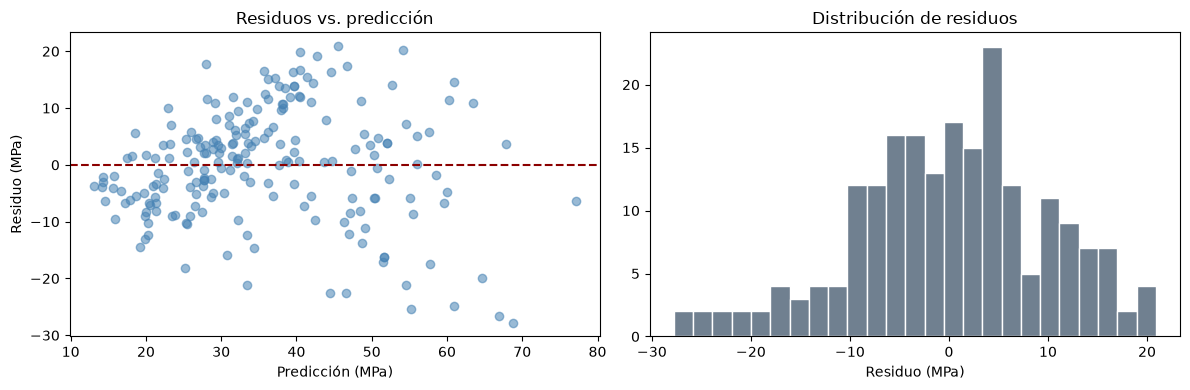

Media de residuos en prueba: 0.018


In [18]:
residuos = y_test.to_numpy() - np.asarray(pred_mejor)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(pred_mejor, residuos, alpha=.55, color="steelblue")
axes[0].axhline(0, color="darkred", linestyle="--")
axes[0].set(xlabel="Predicción (MPa)", ylabel="Residuo (MPa)", title="Residuos vs. predicción")
axes[1].hist(residuos, bins=25, color="slategray", edgecolor="white")
axes[1].set(xlabel="Residuo (MPa)", title="Distribución de residuos")
plt.tight_layout()
plt.show()
print("Media de residuos en prueba:", round(float(residuos.mean()), 4))

## Conclusiones

- Compara RMSE y MAE en prueba: ambos están expresados en MPa y menor es mejor. R² resume la fracción de variabilidad explicada en esa partición.
- La ecuación backward por AIC prioriza ajuste parsimonioso; Ridge y Lasso penalizan coeficientes; los wrappers seleccionan variables mediante validación cruzada.
- Si Random Forest supera al modelo lineal, puede haber relaciones no lineales o interacciones que el modelo lineal no captura.
- La selección y el orden de resultados pueden variar con otra partición. El análisis es predictivo y no establece causalidad.